# GridCast · PJM demand forecasting
## tl;dr
The validation-selected **HistGB_small** achieved **4.38% WAPE** and **4,219 MW MAE** on 8,735 valid 2025 hourly actuals. Its nominal 80% intervals covered **78.6%**. High-demand bias is a material limitation.

This is a **historical forecasting study and decision-support prototype**. It is not a live PJM forecast. Current Power BI Service runtime evidence and genuine screenshots are recorded separately in `powerbi/SERVICE_VALIDATION.md`; Windows PBIP/Desktop compatibility remains untested. Notebook charts are analytical outputs, not Power BI rendering evidence.

## Context & Methods
Forecast once at midnight UTC for the 24 intervals starting at that origin. Known calendar values and demand lags are the only inputs. Train on 2019–2022; select using 2023 MAE; refit once on 2019–2023; calibrate intervals on 2024; freeze and score 2025. No random train/test split.

### Key Assumptions
Previous-hour demand is assumed available at each origin. The revised EIA snapshot cannot prove historical publication latency. UTC origin days differ from PJM market days. No realized target-hour weather enters the model. Intervals use 24 horizon-specific absolute-residual order statistics; serial dependence and changing demand prevent guaranteed coverage.

## Data
[EIA-930 documentation](https://www.eia.gov/electricity/930-content/about.html) describes demand reported by balancing authorities. We select **PJM** and original reported demand, not a sum of overlapping subregions. The workbook marks hour ends; the extraction subtracts one hour. Hourly MWh divided by one hour equals average MW.

The 2019–2025 snapshot has 61,368 unique UTC hours. We mask 167 missing values, seven EIA-flagged corrupt originals, and four reviewed training-only spikes. These 178 hours remain missing as targets. Features use causal prior-week replacements (then prior-day/previous-hour fallback). See `docs/SOURCES.md`, `docs/anomaly_review.csv`, and the checksummed manifest. Ex-post quality flags and revisions make this a retrospective cleaned-data benchmark, not an as-of-vintage deployment replay.


In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd() if (Path.cwd() / 'outputs').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
from gridcast.core import metrics
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 120,
                    'axes.spines.top': False, 'axes.spines.right': False,
                    'axes.titleweight': 'bold', 'axes.labelcolor': '#344256',
                    'font.size': 10, 'axes.grid': True, 'grid.alpha': .15,
                    'savefig.facecolor': 'white'})
BLUE, TEAL, RED, GRAY = '#2559A6', '#107C83', '#C0583E', '#8D98A8'
OUT = ROOT / 'reports/figures'
OUT.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', bbox_inches='tight')
    plt.show()
demand = pd.read_csv(ROOT / 'data/processed/demand_hourly.csv')
demand['DateTimeUTC'] = pd.to_datetime(demand.DateTimeUTC, utc=True)
demand['Local'] = demand.DateTimeUTC.dt.tz_convert('America/New_York')
forecasts = pd.read_csv(ROOT / 'data/powerbi/FactForecast.csv')
forecasts['DateTimeUTC'] = pd.to_datetime(forecasts.DateTimeUTC, utc=True)
scores = pd.read_csv(ROOT / 'outputs/model_metrics.csv')
summary = json.loads((ROOT / 'outputs/run_summary.json').read_text())
quality = json.loads((ROOT / 'outputs/data_quality.json').read_text())
champion = summary['selected_model']
test = forecasts.loc[(forecasts.Model == champion) & (forecasts.Split == 'test') & forecasts.ActualMW.notna()].copy()
test['ErrorMW'] = test.ForecastMW - test.ActualMW
test['AbsErrorMW'] = test.ErrorMW.abs()
test['Month'] = test.DateTimeUTC.dt.month
test['HourLocal'] = test.DateTimeUTC.dt.tz_convert('America/New_York').dt.hour
test['Covered'] = test.ActualMW.between(test.Lower80MW, test.Upper80MW)
assert len(demand) == 61368 and len(test) == 8735
assert demand.ActualMW.isna().sum() == 178
display(pd.DataFrame(quality['annual']).rename(columns={'DateTimeUTC': 'Year'}))
print('Target completeness:', f'{100*demand.ActualMW.notna().mean():.3f}%')

,Year,Hours,ValidActuals,MinMW,MaxMW
0,2019,8760,8758,61336.0,155276.0
1,2020,8784,8731,58480.0,145428.0
2,2021,8760,8757,61374.0,149590.0
3,2022,8760,8737,64063.0,148528.0
4,2023,8760,8735,63543.0,147605.0
5,2024,8784,8737,56260.0,153121.0
6,2025,8760,8735,66131.0,160560.0


Target completeness: 99.710%


## Results
### Demand has recurring seasonal and daily structure
Annual energy below is **observed valid-hour energy**, with missing hours excluded. Completeness accompanies every year; the totals are not estimates of complete annual consumption. The monthly chart uses mean hourly demand, avoiding unequal month lengths. Local-hour profiles handle Eastern daylight-saving time; local dates at UTC boundaries can include adjacent calendar years.

,MeanMW,PeakMW,ObservedEnergyMWh,ValidHours,TotalHours,CoveragePct
DateTimeUTC,,,,,,
2019,91359.38,155276.0,800125472.0,8758,8760,99.98
2020,87650.28,145428.0,765274628.0,8731,8784,99.40
2021,90899.25,149590.0,796004775.0,8757,8760,99.97
2022,92483.54,148528.0,808028705.0,8737,8760,99.74
2023,89632.50,147605.0,782939863.0,8735,8760,99.71
2024,92861.18,153121.0,811328090.0,8737,8784,99.46
2025,96290.39,160560.0,841096525.0,8735,8760,99.71


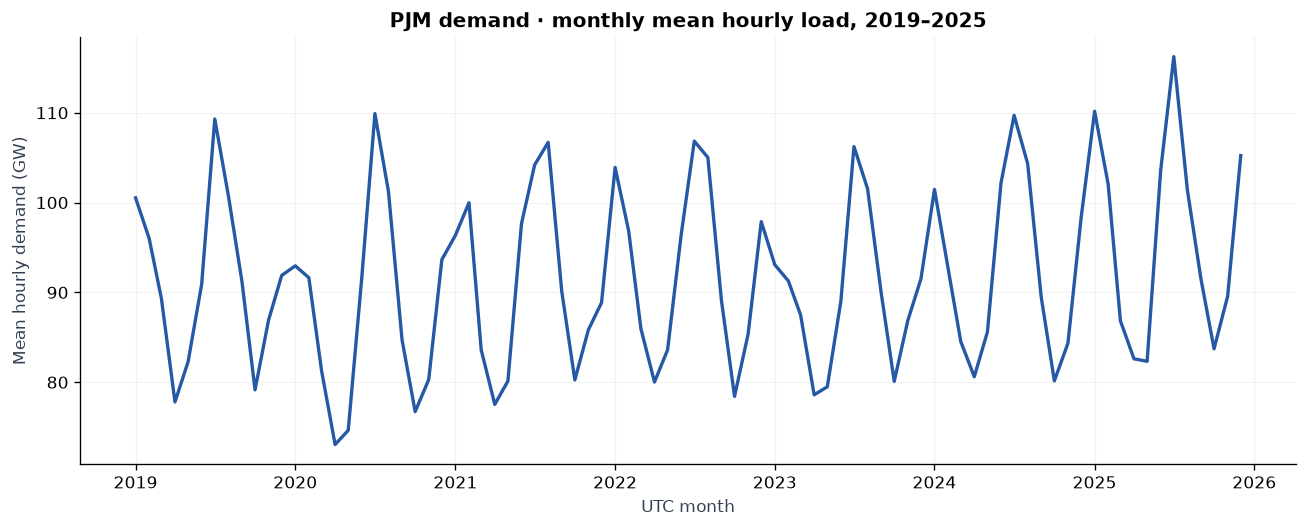

In [2]:
annual = demand.groupby(demand.DateTimeUTC.dt.year).ActualMW.agg(
    MeanMW='mean', PeakMW='max', ObservedEnergyMWh='sum', ValidHours='count', TotalHours='size')
annual['CoveragePct'] = 100 * annual.ValidHours / annual.TotalHours
annual.to_csv(ROOT / 'outputs/annual_demand.csv')
display(annual.round(2))
monthly_demand = demand.set_index('DateTimeUTC').ActualMW.resample('MS').mean() / 1000
fig, ax = plt.subplots()
ax.plot(monthly_demand.index, monthly_demand, color=BLUE, lw=2)
ax.set(title='PJM demand · monthly mean hourly load, 2019–2025', ylabel='Mean hourly demand (GW)', xlabel='UTC month')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
savefig('demand_trend')

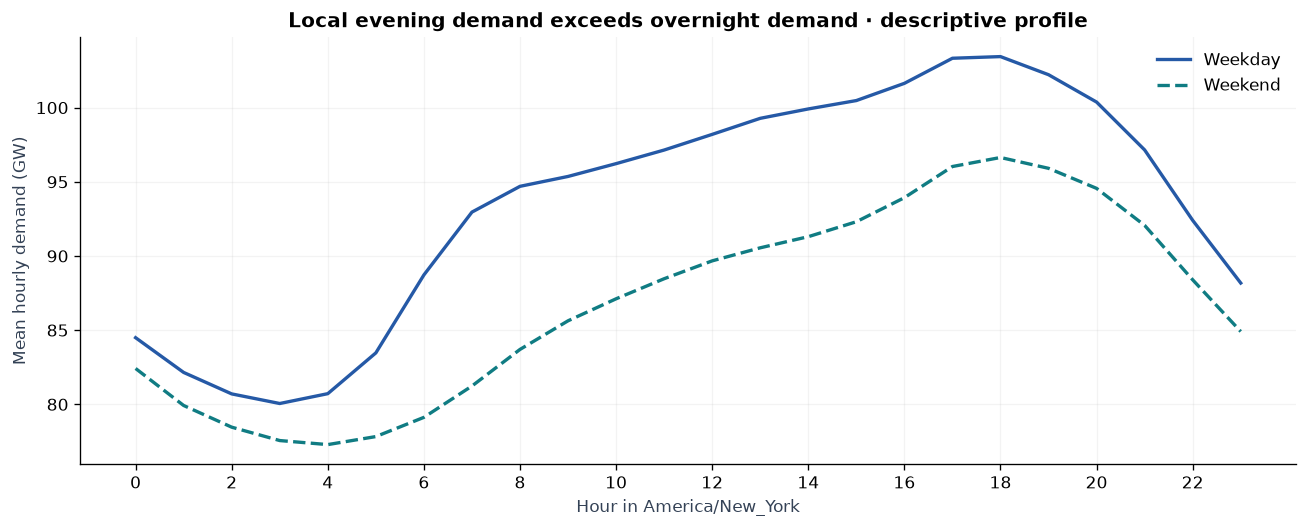

In [3]:
profile = demand.assign(Weekend=demand.Local.dt.day_of_week >= 5, Hour=demand.Local.dt.hour).groupby(['Weekend', 'Hour']).ActualMW.mean().unstack(0) / 1000
fig, ax = plt.subplots()
for key, label, color, style in [(False, 'Weekday', BLUE, '-'), (True, 'Weekend', TEAL, '--')]:
    ax.plot(profile.index, profile[key], label=label, color=color, ls=style, lw=2)
ax.set(title='Local evening demand exceeds overnight demand · descriptive profile', xlabel='Hour in America/New_York', ylabel='Mean hourly demand (GW)', xticks=range(0, 24, 2))
ax.legend(frameon=False)
savefig('hourly_profile')

### A modest model improves MAE, with a tradeoff on larger errors
All five candidates score identical valid hours. The smaller histogram gradient boosting model was selected **before** the test year using 2023 MAE. Daily persistence is the stronger naïve test comparator. Ridge has slightly lower test RMSE than the selected model; selection remains tied to the predeclared MAE criterion. These results do not establish superiority over PJM's own operational forecasts, which use different information and issue times.

,Model,Split,N,MAE_MW,RMSE_MW,WAPE_pct,Bias_MW
0,DailyNaive,validation,8735,4466.00,5977.72,4.98,-27.64
1,WeeklyNaive,validation,8735,6653.09,9430.97,7.42,273.59
2,Ridge,validation,8735,3729.63,4866.16,4.16,404.94
3,HistGB_small,validation,8735,3334.84,4536.86,3.72,237.35
4,HistGB_large,validation,8735,3384.03,4646.06,3.78,311.49
10,DailyNaive,test,8735,4863.03,6438.58,5.05,-62.47
11,WeeklyNaive,test,8735,8418.11,11583.51,8.74,-175.29
12,Ridge,test,8735,4331.87,5704.55,4.50,-1177.18
13,HistGB_small,test,8735,4219.45,5793.44,4.38,-1464.97
14,HistGB_large,test,8735,4487.09,6225.50,4.66,-1826.37


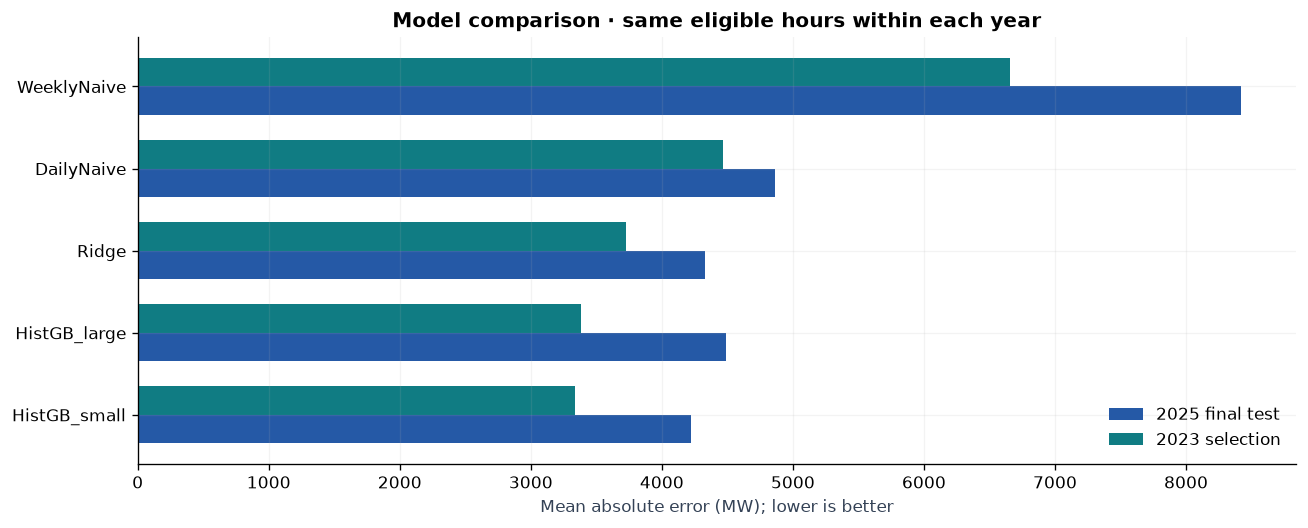

MAE reduction against stronger naïve comparator: 13.23%


In [4]:
display(scores.loc[scores.Split.isin(['validation', 'test']), ['Model', 'Split', 'N', 'MAE_MW', 'RMSE_MW', 'WAPE_pct', 'Bias_MW']].round(2))
comparison = scores.loc[scores.Split.isin(['validation', 'test'])].pivot(index='Model', columns='Split', values='MAE_MW').sort_values('validation')
fig, ax = plt.subplots()
comparison.rename(columns={'validation': '2023 selection', 'test': '2025 final test'}).plot.barh(ax=ax, color=[BLUE, TEAL], width=.7)
ax.set(title='Model comparison · same eligible hours within each year', xlabel='Mean absolute error (MW); lower is better', ylabel='')
ax.legend(frameon=False)
savefig('model_comparison')
base_mae = float(scores.loc[(scores.Model == 'DailyNaive') & (scores.Split == 'test'), 'MAE_MW'].iloc[0])
reduction = 100 * (1 - summary['test_metrics']['MAE_MW'] / base_mae)
print(f'MAE reduction against stronger naïve comparator: {reduction:.2f}%')

### Check paired improvement with blocks of consecutive days
This descriptive bootstrap resamples seven-day blocks of the paired test losses, preserving short-range dependence within blocks. It estimates uncertainty for this particular year's mean MAE difference; one year and a chosen block length do not establish future-year performance or causal impact. Positive values favor the selected model.

In [5]:
daily_baseline = forecasts.loc[(forecasts.Model == 'DailyNaive') & (forecasts.Split == 'test') & forecasts.ActualMW.notna(), ['DateTimeUTC', 'ForecastMW']].rename(columns={'ForecastMW': 'BaselineMW'})
paired = test.merge(daily_baseline, on='DateTimeUTC', validate='one_to_one')
paired['GainMW'] = (paired.BaselineMW - paired.ActualMW).abs() - paired.AbsErrorMW
daily = paired.groupby(paired.DateTimeUTC.dt.floor('D')).agg(GainSum=('GainMW', 'sum'), N=('GainMW', 'size'))
rng = np.random.default_rng(42)
sample_gains = []
for _ in range(2000):
    starts = rng.integers(0, len(daily), size=int(np.ceil(len(daily)/7)))
    ids = np.concatenate([(np.arange(start, start+7) % len(daily)) for start in starts])[:len(daily)]
    block = daily.iloc[ids]
    sample_gains.append(block.GainSum.sum()/block.N.sum())
ci = np.quantile(sample_gains, [.025, .975])
bootstrap = {'method': 'paired circular moving-block bootstrap, 7-day blocks, 2000 repetitions, seed42',
             'mean_MAE_gain_MW': float(paired.GainMW.mean()), 'lower95_MW': float(ci[0]), 'upper95_MW': float(ci[1])}
(ROOT / 'outputs/paired_bootstrap.json').write_text(json.dumps(bootstrap, indent=2))
display(pd.Series(bootstrap))

method              paired circular moving-block bootstrap, 7-day ...
mean_MAE_gain_MW                                           643.580688
lower95_MW                                                  254.86937
upper95_MW                                                1025.602045
dtype: object

### Errors concentrate in high-demand periods
The high-demand threshold is the 90th percentile of **initial training** demand, fixed before later years. This subset is diagnostic, not a separate model-selection set. Large negative errors mean underprediction. Nominal 80% intervals cover only about 48% of high-demand test hours. The 25 missing test actuals form a contiguous gap around the Eastern autumn clock change; observed-hour accuracy does not validate that missing transition. Weather sensitivity is a plausible next hypothesis, but weather and causal drivers have not been measured here.

,MAE_MW,Bias_MW,Coverage,N
Month,,,,
1,5650.151,-3557.072,0.626,744
2,4977.453,-2161.431,0.661,672
3,3422.181,53.330,0.870,744
4,2446.453,-659.845,0.969,720
5,2762.734,818.680,0.933,744
6,6245.428,-5026.194,0.665,720
7,5506.170,-2891.359,0.630,744
8,4806.192,673.630,0.757,744
9,4207.009,-2337.975,0.800,720


/var/folders/p9/t7x_16px46v5mtph66tjgpk80000gn/T/ipykernel_90641/3766678583.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(worst.head(6).round(1))


,DateTimeUTC,ActualMW,ForecastMW,ErrorMW,AbsErrorMW
118173,2025-06-23 21:00:00+00:00,160560.0,130276.4,-30283.6,30283.6
118174,2025-06-23 22:00:00+00:00,160299.0,130068.8,-30230.2,30230.2
118172,2025-06-23 20:00:00+00:00,158769.0,128879.2,-29889.8,29889.8
118170,2025-06-23 18:00:00+00:00,155369.0,125498.4,-29870.6,29870.6
118175,2025-06-23 23:00:00+00:00,158200.0,128851.2,-29348.8,29348.8
118169,2025-06-23 17:00:00+00:00,153347.0,124253.9,-29093.1,29093.1


Residual autocorrelation at elapsed hourly lags: {'1': 0.9729390790040562, '24': 0.3250244450457101, '168': 0.12216592090437893}


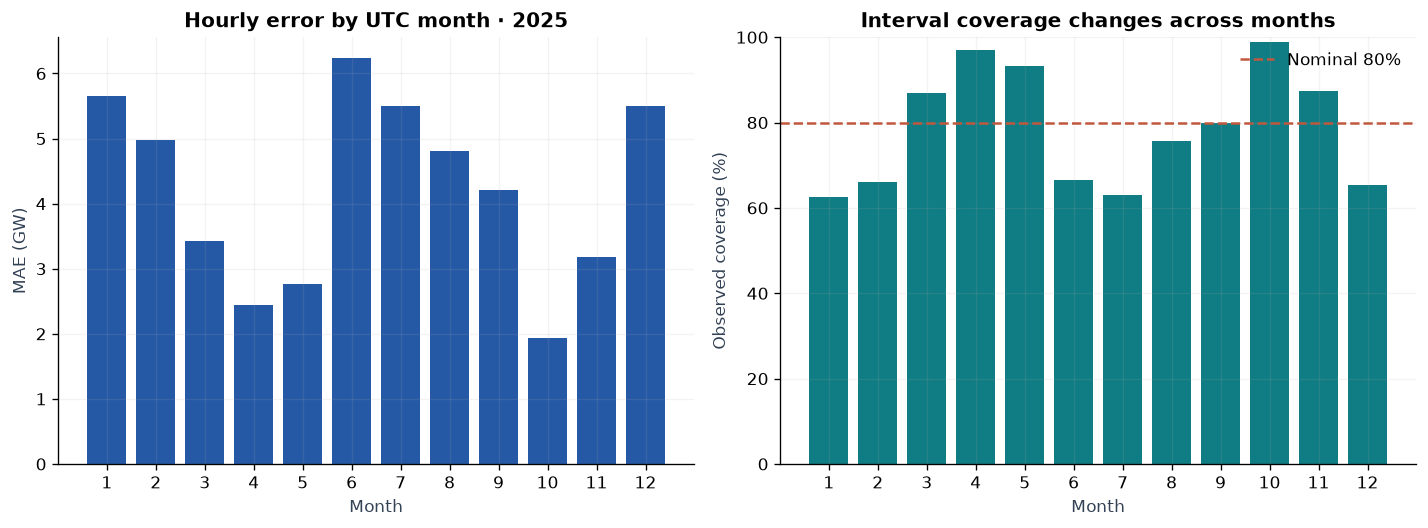

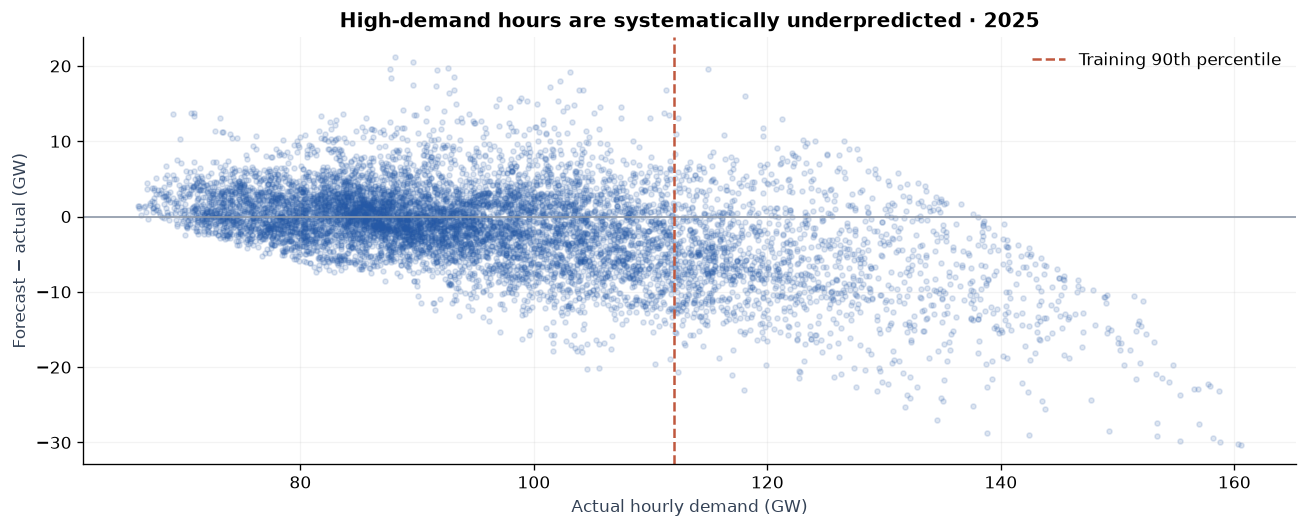

In [6]:
month = test.groupby('Month').agg(MAE_MW=('AbsErrorMW', 'mean'), Bias_MW=('ErrorMW', 'mean'), Coverage=('Covered', 'mean'), N=('ActualMW', 'size'))
month.to_csv(ROOT / 'outputs/test_monthly_diagnostics.csv')
display(month.round(3))
worst = test.nlargest(20, 'AbsErrorMW')[['DateTimeUTC', 'ActualMW', 'ForecastMW', 'ErrorMW', 'AbsErrorMW']]
worst.to_csv(ROOT / 'outputs/largest_test_errors.csv', index=False)
display(worst.head(6).round(1))
for column in ('HourLocal', 'HorizonHours'):
    test.groupby(column).agg(MAE_MW=('AbsErrorMW', 'mean'), Bias_MW=('ErrorMW', 'mean'), Coverage=('Covered', 'mean'), N=('ActualMW', 'size')).to_csv(ROOT / f'outputs/diagnostics_by_{column}.csv')
weekday = test.assign(WeekdayLocal=test.DateTimeUTC.dt.tz_convert('America/New_York').dt.day_of_week)
weekday.groupby('WeekdayLocal').agg(MAE_MW=('AbsErrorMW', 'mean'), Bias_MW=('ErrorMW', 'mean'), N=('ActualMW', 'size')).to_csv(ROOT / 'outputs/diagnostics_by_weekday.csv')
regular_error = test.set_index('DateTimeUTC').ErrorMW.reindex(pd.date_range('2025-01-01', '2025-12-31 23:00', freq='h', tz='UTC'))
autocorrelation = {str(lag): float(regular_error.autocorr(lag)) for lag in (1, 24, 168)}
(ROOT / 'outputs/residual_autocorrelation.json').write_text(json.dumps(autocorrelation, indent=2))
print('Residual autocorrelation at elapsed hourly lags:', autocorrelation)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(month.index, month.MAE_MW/1000, color=BLUE)
axes[0].set(title='Hourly error by UTC month · 2025', xlabel='Month', ylabel='MAE (GW)', xticks=range(1,13))
axes[1].bar(month.index, 100*month.Coverage, color=TEAL)
axes[1].axhline(80, color=RED, ls='--', label='Nominal 80%')
axes[1].set(title='Interval coverage changes across months', xlabel='Month', ylabel='Observed coverage (%)', ylim=(0,100), xticks=range(1,13))
axes[1].legend(frameon=False)
savefig('seasonal_errors')
fig, ax = plt.subplots()
ax.scatter(test.ActualMW/1000, test.ErrorMW/1000, alpha=.15, s=9, color=BLUE, rasterized=True)
ax.axhline(0, color=GRAY, lw=1)
ax.axvline(summary['training_p90_MW']/1000, color=RED, ls='--', label='Training 90th percentile')
ax.set(title='High-demand hours are systematically underpredicted · 2025', xlabel='Actual hourly demand (GW)', ylabel='Forecast − actual (GW)')
ax.legend(frameon=False)
savefig('high_demand_bias')

### A stress week makes the limitation visible
The following view deliberately shows the week containing the highest valid 2025 demand. It is a diagnostic stress view selected after evaluation, not a representative random week. The bands are **pointwise** 80% prediction intervals, not a simultaneous confidence band for the whole path.

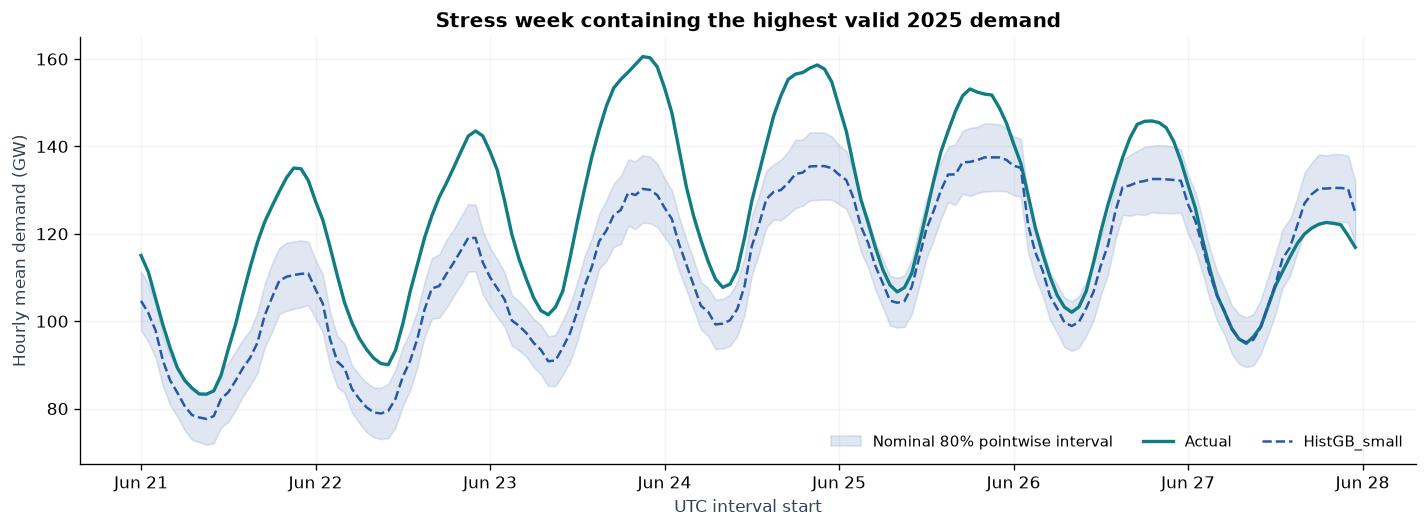

In [7]:
peak_time = test.loc[test.ActualMW.idxmax(), 'DateTimeUTC']
begin = peak_time.floor('D') - pd.Timedelta(days=2)
week = test.loc[(test.DateTimeUTC >= begin) & (test.DateTimeUTC < begin + pd.Timedelta(days=7))]
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.fill_between(week.DateTimeUTC, week.Lower80MW/1000, week.Upper80MW/1000, color=BLUE, alpha=.14, label='Nominal 80% pointwise interval')
ax.plot(week.DateTimeUTC, week.ActualMW/1000, color=TEAL, lw=2, label='Actual')
ax.plot(week.DateTimeUTC, week.ForecastMW/1000, color=BLUE, lw=1.5, ls='--', label=champion)
ax.set(title='Stress week containing the highest valid 2025 demand', ylabel='Hourly mean demand (GW)', xlabel='UTC interval start')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.legend(frameon=False, ncol=3, fontsize=9)
savefig('stress_week')

### The next-day pipeline output is historical and unscored
The final model remains frozen after fitting through 2023 so its calibration and test provenance stay consistent. The pipeline issues a demonstration for **1 January 2026 UTC** using the final 2025 inputs. This is not a forecast for the present date and has no scored actuals in this project.

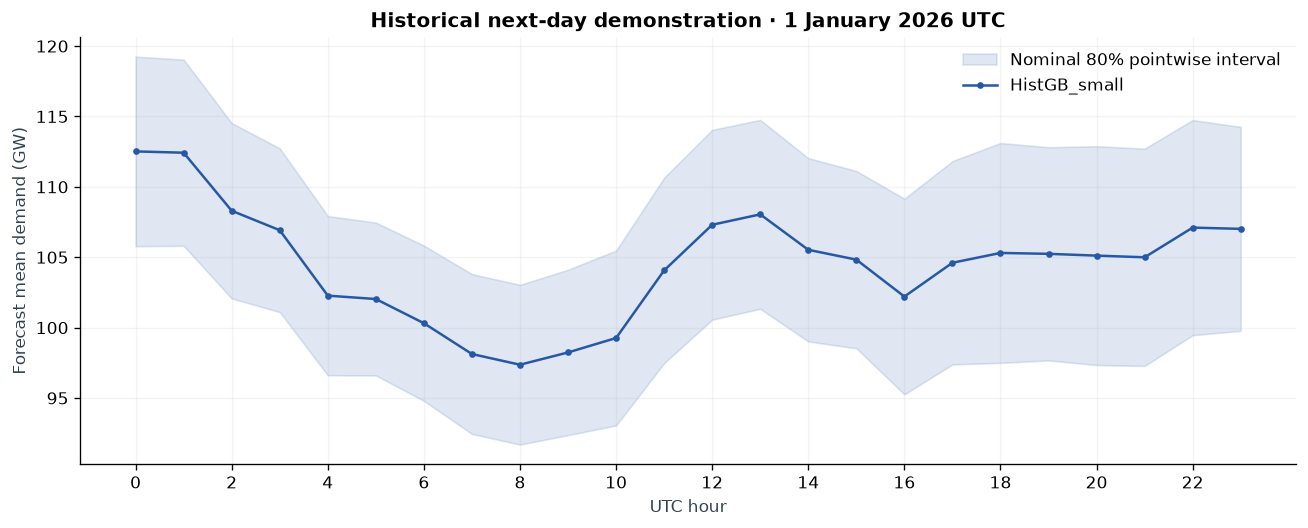

/var/folders/p9/t7x_16px46v5mtph66tjgpk80000gn/T/ipykernel_90641/3136337160.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(future[['DateTimeUTC', 'ForecastMW', 'Lower80MW', 'Upper80MW']].head(6).round(1))


,DateTimeUTC,ForecastMW,Lower80MW,Upper80MW
131520,2026-01-01 00:00:00+00:00,112517.8,105782.2,119253.5
131521,2026-01-01 01:00:00+00:00,112425.3,105812.3,119038.3
131522,2026-01-01 02:00:00+00:00,108301.4,102069.8,114533.0
131523,2026-01-01 03:00:00+00:00,106918.9,101101.4,112736.4
131524,2026-01-01 04:00:00+00:00,102270.8,96615.5,107926.0
131525,2026-01-01 05:00:00+00:00,102031.7,96601.8,107461.7


In [8]:
future = forecasts.loc[forecasts.Split == 'future'].copy()
assert len(future) == 24 and future.ActualMW.isna().all()
fig, ax = plt.subplots()
ax.fill_between(future.HourUTC, future.Lower80MW/1000, future.Upper80MW/1000, color=BLUE, alpha=.14, label='Nominal 80% pointwise interval')
ax.plot(future.HourUTC, future.ForecastMW/1000, color=BLUE, marker='o', ms=3, label=champion)
ax.set(title='Historical next-day demonstration · 1 January 2026 UTC', xlabel='UTC hour', ylabel='Forecast mean demand (GW)', xticks=range(0,24,2))
ax.legend(frameon=False)
savefig('historical_next_day')
display(future[['DateTimeUTC', 'ForecastMW', 'Lower80MW', 'Upper80MW']].head(6).round(1))

## Takeaways
- **Use the model as a review aid.** It improves the declared MAE objective versus persistence, but high-demand errors are materially larger than average.
- **Escalate high-demand profiles for review.** On the fixed high-demand subset, MAE is 7,892 MW and bias is -6,593 MW. This motivates further experiments, not an operational reserve rule.
- **Show interval calibration honestly.** Aggregate coverage is 78.6% with a mean width of 13,185 MW. Monthly coverage varies; a nominal label is not a guarantee.
- **Prioritize a weather and holiday experiment using a new holdout.** Use archived issued forecasts, regionally representative station weights, and an explicit latency rule. Do not retune on the already examined 2025 test set and call it untouched again.
- **Keep portfolio claims bounded.** No dispatch trial, price data, outage outcome, emissions model, or realized savings analysis was performed. The Power BI source is authored; native Desktop verification remains open.

Source: U.S. Energy Information Administration, PJM balancing authority workbook, retrieved 27 October 2026. Observation window: 2019–2025. Full source and transformation receipt: `docs/SOURCES.md` and `data/raw/eia_pjm_manifest.json`.
